# Optogenetically tagged cells

Raster plots and peri-event time histograms for representative ChAT, vGluT, and vGAT neurons aligned to laser onset.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Setup

In [2]:
# Locate the data directory whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (path for path in project_candidates if (path / "data" / "tag").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate data/tag from the current directory.")

data_path = project_root / "data" / "tag"

# Acquisition and peri-event parameters.
sampling_rate_hz = 30_000
pre_time_s = 0.200
post_time_s = 0.200
bin_width_s = 0.005  # 5 ms

# Shared figure style.
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams.update({"font.size": 18})
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.spines.top"] = False

## Plotting function

In [3]:
def plot_laser_response(tag, unit_id):
    """Plot a spike raster and mean firing rate aligned to laser onset."""
    spike_file = data_path / f"{tag}_time_cluster_shank_sua.txt"
    laser_file = data_path / f"{tag}_laseron.npy"

    if not spike_file.is_file() or not laser_file.is_file():
        raise FileNotFoundError(f"Missing input files for {tag} in {data_path}")

    spike_data = np.loadtxt(spike_file)
    spikes = pd.DataFrame(spike_data.T, columns=["time", "unit_id", "shank"])
    selected_spikes = spikes[spikes["unit_id"] == unit_id].reset_index(drop=True)
    if selected_spikes.empty:
        raise ValueError(f"Unit {unit_id} was not found in {spike_file.name}")

    # Convert laser-onset sample indices to seconds.
    laser_onsets_s = np.load(laser_file) / sampling_rate_hz
    histogram_edges = np.arange(
        -pre_time_s,
        post_time_s + bin_width_s,
        bin_width_s,
    )
    trial_counts = []

    fig, (raster_ax, histogram_ax) = plt.subplots(
        2,
        1,
        figsize=(10, 6),
        gridspec_kw={"height_ratios": [2, 2]},
    )

    # Align the selected unit's spikes to every laser onset.
    for trial_index, laser_time_s in enumerate(laser_onsets_s):
        spikes_in_window = selected_spikes[
            (selected_spikes["time"] >= laser_time_s - pre_time_s)
            & (selected_spikes["time"] <= laser_time_s + post_time_s)
        ].copy()
        aligned_spikes_s = spikes_in_window["time"] - laser_time_s

        raster_ax.vlines(
            aligned_spikes_s,
            trial_index + 0.5,
            trial_index + 1.5,
            color="black",
        )
        counts, _ = np.histogram(aligned_spikes_s, bins=histogram_edges)
        trial_counts.append(counts)

    # Mark the 10 ms laser pulse and display trials from top to bottom.
    raster_ax.fill_between([0, 0.01], -1, -3, color="navy", alpha=0.4)
    raster_ax.set(
        xlabel="Time (s)",
        ylabel="Trial",
        xlim=(-pre_time_s, post_time_s),
        ylim=(len(laser_onsets_s), -3),
        title=f"Laser response — {tag}, unit {unit_id}",
    )

    # Convert the mean spike count per bin to firing rate in hertz.
    mean_firing_rate_hz = np.mean(trial_counts, axis=0) / bin_width_s
    histogram_times_s = np.arange(-pre_time_s, post_time_s, bin_width_s)
    histogram_ax.step(
        histogram_times_s + bin_width_s,
        mean_firing_rate_hz,
        where="mid",
        color="black",
    )
    histogram_ax.set(
        xlabel="Time (s)",
        ylabel="Firing rate (Hz)",
        xlim=(-pre_time_s, post_time_s),
    )

    plt.tight_layout()
    plt.show()
    return mean_firing_rate_hz

## ChAT representative neuron

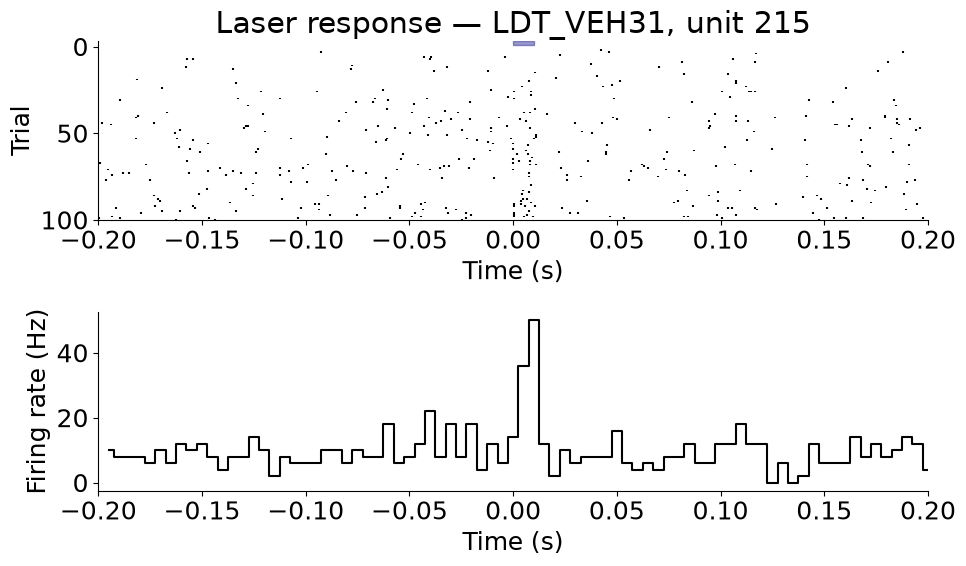

In [4]:
chat_mean_firing_rate = plot_laser_response("LDT_VEH31", unit_id=215)

## vGluT representative neuron

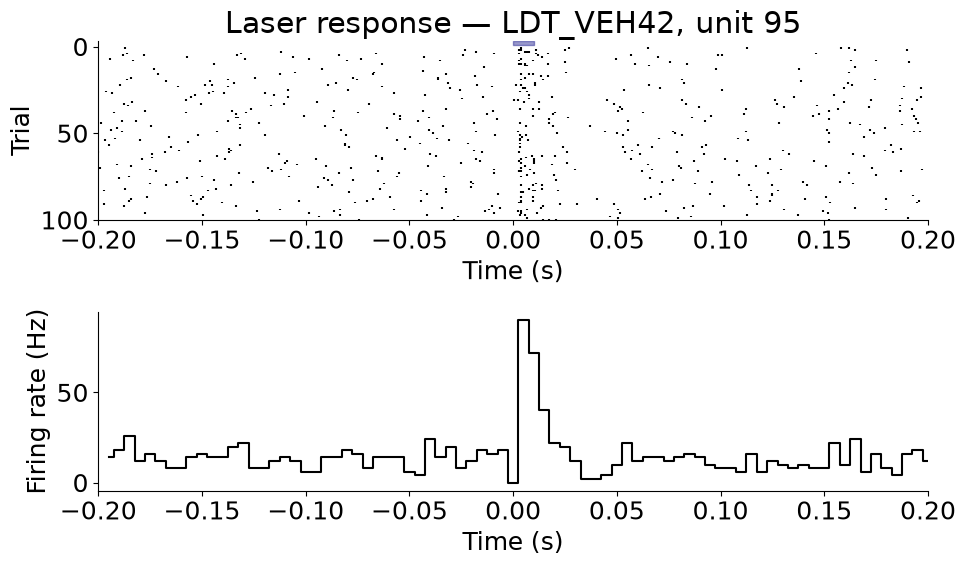

In [5]:
vglut_mean_firing_rate = plot_laser_response("LDT_VEH42", unit_id=95)

## vGAT representative neuron

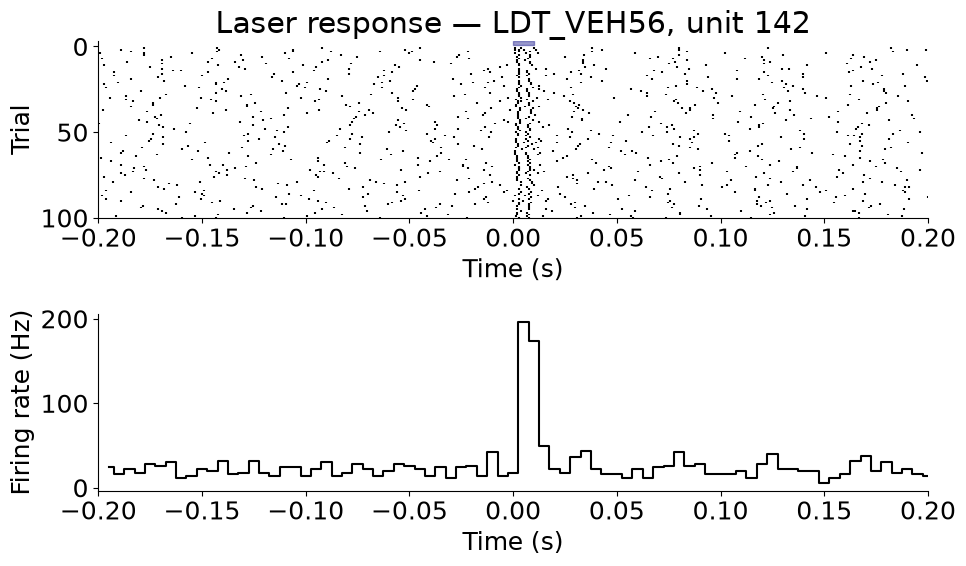

In [6]:
vgat_mean_firing_rate = plot_laser_response("LDT_VEH56", unit_id=142)